# Eye v1: challenges

A follow-up to `eye_v1.ipynb` after the October 2026 review. Each section answers one review point, using the review's numbering.

| # | Review point | What this notebook does |
|---|---|---|
| 1 | Pitch family and the umpire model | Re-runs the family test properly and shows where family does and doesn't matter |
| 2 | Is eye just chase rate? | Compares eye to chase % and good decision % |
| 3 | Team decisions | Removes bunts everywhere; shows results with 3-0 takes removed |
| 4 | Swing value only learns from swings that happened | Limitation, with evidence |
| 5 | No pitch quality in the swing models | Note on the future development |
| 7 | The app shows raw Eye/100 | Explains shrinkage and checks it against the data |
| 9 | In-sample scoring | Tests for leakage; corrects the count-table claim |

Point 6 (neutral umpire zone) and point 8 (small levels use D1 settings, intentional) need no work here. **Height is still ignored.**

**Data:** the pipeline_v2 season parquets, `pipeline_v2/serving/pitches/D1/{year}/d1_{year}.parquet`, D1 2022–2026. Each pitch's run value comes from its own season's RE288 table.

**Model:** the shipped code in `backend/models/eye_v1.py` (`prepare`, `count_run_values`, `EyeModel`), so the numbers here come from the production model. One change: **bunts are removed** from training and scoring (section 3). As in production, the models train on verified games and score every game.

Runtime: about 10 minutes. The models are refit for every season, and sections 1 and 9 fit extra ones. LightGBM's multithreaded fits aren't bit-identical from run to run, so a re-run can move numbers in the third decimal; the text quotes this run.

## Setup

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import polars as pl
import lightgbm as lgb
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.metrics import log_loss

# repo root = the first folder up from here that holds pipeline_v2
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pipeline_v2").is_dir())
sys.path.insert(0, str(REPO))
from backend.models import eye_v1, rv_store
from delispice_app.report import ZONE, _eff_type_expr, _family_expr   # the app's zone and pitch-family split

SEASONS = REPO / "pipeline_v2" / "serving" / "pitches" / "D1"
ARTIFACTS = REPO / "pipeline_v2" / "artifacts"
YEARS = ["2022", "2023", "2024", "2025", "2026"]
MIN_N = 200    # decisions a hitter needs in a season to enter the hitter-level comparisons

pl.Config.set_tbl_rows(25)
pl.Config.set_tbl_cols(20)
pl.Config.set_float_precision(3)
pl.Config.set_tbl_hide_dataframe_shape(True)

# chart style: recessive axes, one blue for single series, blue <-> red around gray for differences
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
SEQ = LinearSegmentedColormap.from_list("seq", ["#fcfcfb", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", ["#1c5cab", "#86b6ef", "#f0efec", "#f19c9b", "#c23b3a"])
plt.rcParams.update({"axes.edgecolor": "#c3c2b7", "axes.labelcolor": MUTED, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.titlecolor": INK, "axes.titlesize": 11,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})

### Load every season

`decisions()` is production's `prepare()`: competitive swing/take calls only (no HBP or intentional balls), inside the plate-location bounds, deduplicated on `PitchUID`. Three flags are added on top:

- `is_bunt`: `TaggedHitType == "Bunt"`
- `in_zone`: the app's rulebook zone (`delispice_app/report.py`, 1.5–3.38 ft high, ±0.83 ft wide)
- `report_family`: the family the hitter reports split on (`TaggedPitchType`, falling back to `AutoPitchType`)

`outcomes()` uses every pitch to get each hitter-season's walk %, strikeout % and realized RV/100.

In [2]:
COLS = ["PitchUID", "GameUID", "Batter", "BatterTeam", "BatterSide", "AutoPitchType", "TaggedPitchType",
        "TaggedHitType", "Balls", "Strikes", "PitchCall", "KorBB", "PlateLocHeight", "PlateLocSide",
        "is_verified", *rv_store.ROW_STATE]
KEEP = ["PitchUID", "GameUID", "Batter", "BatterTeam", "BatterSide", "Balls", "Strikes", "PitchCall",
        "PlateLocHeight", "PlateLocSide", "PitchFamily", "swung", "run_value", "is_verified",
        "is_bunt", "in_zone", "report_family"]
IN_ZONE = (pl.col("PlateLocSide").abs() <= ZONE["h"]) & pl.col("PlateLocHeight").is_between(ZONE["b"], ZONE["t"])


def load_season(year):
    """Every D1 pitch of one season, with its realized run value in that season's RE288."""
    raw = pl.read_parquet(SEASONS / year / f"d1_{year}.parquet", columns=COLS)
    return raw.with_columns(rv_store.attach_rv(raw, "D1", year).alias("run_value"))


def decisions(raw):
    """The eye population (production's prepare) plus the flags this notebook needs."""
    d = eye_v1.prepare(raw)
    return d.with_columns(pl.col("TaggedHitType").eq_missing("Bunt").alias("is_bunt"),   # null hit type -> not a bunt
                          IN_ZONE.alias("in_zone"),
                          _family_expr(_eff_type_expr(d)).alias("report_family")).select(KEEP)


def outcomes(raw):
    """Per hitter-season results from EVERY pitch: walk %, strikeout %, realized RV/100 pitches."""
    pa_end = pl.col("KorBB").is_in(["Walk", "Strikeout"]) | pl.col("PitchCall").is_in(["InPlay", "HitByPitch"])
    return raw.unique("PitchUID").group_by("Batter").agg(
        pa_end.sum().alias("PA"),
        ((pl.col("KorBB") == "Walk").sum() / pa_end.sum()).alias("bb"),
        ((pl.col("KorBB") == "Strikeout").sum() / pa_end.sum()).alias("k"),
        (pl.col("run_value").mean() * 100).alias("rv100"))


dec, OUT, rows = {}, {}, []
for y in YEARS:
    raw = load_season(y)
    dec[y], OUT[y] = decisions(raw), outcomes(raw)
    rows.append({"season": y, "pitches": raw.height, "decisions": dec[y].height,
                 "verified %": 100 * dec[y]["is_verified"].mean(), "bunts": int(dec[y]["is_bunt"].sum())})
del raw
pl.DataFrame(rows)

season,pitches,decisions,verified %,bunts
str,i64,i64,f64,i64
"""2022""",855274,819534,98.521,3838
"""2023""",1168885,1126147,98.879,5379
"""2024""",1487602,1428313,98.080,7070
"""2025""",1791476,1729923,98.828,9147
"""2026""",2024927,1954850,98.551,10228


### Fit each season (bunts removed)

This is the population every later section uses: the production model, refit per season without bunts. `S[year]` holds every scored decision with its pieces (`p_strike`, `p_swing`, `ev_swing`, `ev_take`) and its `eye`. `H[year]` has one row per hitter.

In [3]:
def fit_and_score(year, d):
    """Production EyeModel for one season, bunts removed. Train on verified games, score every game."""
    count_rv = eye_v1.count_run_values(eye_v1.load_re_matrix("D1", year))
    pop = d.filter(~pl.col("is_bunt"))
    model = eye_v1.EyeModel().fit(pop.filter(pl.col("is_verified")), count_rv)
    scored = model.components(pop).with_columns(
        ((pl.col("swung") - pl.col("p_swing")) * (pl.col("ev_swing") - pl.col("ev_take"))).alias("eye"))
    return model, scored


def per_hitter(s, drop=None):
    """One row per hitter: decisions, Eye/100 (raw mean x 100), and the simple discipline rates.
    `drop` is an optional condition for decisions to leave out (used in section 3)."""
    if drop is not None:
        s = s.filter(~drop)
    swing, take = pl.col("swung") == 1, pl.col("swung") == 0
    return s.group_by("Batter").agg(
        pl.len().alias("n"),
        (pl.col("eye").mean() * 100).alias("eye100"),
        pl.col("swung").filter(~pl.col("in_zone")).mean().alias("chase"),
        pl.col("swung").filter(pl.col("in_zone")).mean().alias("zswing"),
        ((pl.col("in_zone") & swing) | (~pl.col("in_zone") & take)).mean().alias("good_dec"),
        pl.col("BatterTeam").mode().first().alias("team"))


def pairs(H, min_n=MIN_N):
    """Returning hitters: season t joined to season t+1 (suffix _next), with >= min_n decisions in both."""
    return pl.concat([H[a].filter(pl.col("n") >= min_n)
                          .join(H[b].filter(pl.col("n") >= min_n), on="Batter", suffix="_next")
                          .with_columns(pl.lit(f"{a}→{b}").alias("pair"))
                      for a, b in zip(YEARS[:-1], YEARS[1:])])


def yoy(P, col):
    return P.select(pl.corr(col, col + "_next")).item()


models, S = {}, {}
for y in YEARS:
    models[y], S[y] = fit_and_score(y, dec[y])
    print(f"{y}: {S[y].height:,} decisions scored")
H = {y: per_hitter(S[y]).join(OUT[y], on="Batter", how="left") for y in YEARS}

2022: 815,696 decisions scored
2023: 1,120,768 decisions scored
2024: 1,421,243 decisions scored
2025: 1,720,776 decisions scored
2026: 1,944,622 decisions scored


## 1. Pitch family: where it matters and where it doesn't

The review's claim was narrow: **pitch family doesn't help the umpire model**. That isn't the same as "pitch family doesn't matter." There are three separate questions:

1. **Does family help predict the umpire's call?** This is a feature in the umpire model, which prices a take. Answer below: no.
2. **Does family help predict whether the league swings, and what a swing is worth?** These are features in the swing model and the swing-value model. For the swing model, yes, by a lot; for swing value, a little.
3. **Is it valid to split a hitter's Eye/100 by family, as the hitter reports do?** Yes. A split just adds up the hitter's per-pitch eye on fastballs, breaking balls and offspeed separately. It doesn't depend on which features the umpire model uses. Because of question 2, every pitch's score already knows its family: a chased slider is priced as a slider chase, not as a generic pitch in that spot.

So family stays exactly where it is. The only correction is *why* the umpire model leaves it out: not "it hurt", but "it adds nothing, and we want the call to depend on location only".

**What went wrong in `eye_v1.ipynb` cell 1:** it ran `ump_model.fit(X_val, y_val, eval_set=[(X_te, y_te)])`. That trained on the small validation slice (170k pitches, 16% of the data), used the test set to choose the number of trees, then scored the model on that same test set. A model trained on a sixth of the data with an extra feature can easily look worse, and that's where 0.206 → 0.212 came from.

### 1a. The test, done properly

One game-level split for every model: train (64% of games), val (16%, only picks the tree count) and test (20%, scored once). Each model is fit on the same rows with and without family. Lower loss is better.

The loss alone hides how much there was to gain. **Skill** = 1 − loss ÷ (loss of predicting the training average every time): the share of the loss the model removes. For swing value it is the R². Most of a swing's run value is contact luck that no feature can explain, so its skill is small, and a feature's contribution should be judged against that small number, not against the total loss.

In [4]:
LOC = ["BatterSide", "Balls", "Strikes", "PlateLocHeight", "PlateLocSide"]   # the umpire model's features
FAM = ["PitchFamily"]

pdf = (dec["2026"].filter(pl.col("is_verified"), ~pl.col("is_bunt"))
                  .select("GameUID", "swung", "PitchCall", "run_value", *LOC, *FAM).to_pandas())
pdf["PitchFamily"] = pdf["PitchFamily"].astype("category")

games = pdf["GameUID"].to_numpy()
trval, test = next(GroupShuffleSplit(test_size=0.2, n_splits=1, random_state=42).split(pdf, groups=games))
tr, va = next(GroupShuffleSplit(test_size=0.2, n_splits=1, random_state=1).split(trval, groups=games[trval]))
part = np.full(len(pdf), "test", dtype=object)
part[trval[tr]], part[trval[va]] = "train", "val"
pdf["part"] = part


def heldout(frame, feats, y, objective):
    """Fit on train games, pick the tree count on val games, score the test games once.
    Returns (trees, test loss, test loss of always predicting the training average)."""
    Model = lgb.LGBMClassifier if objective == "binary" else lgb.LGBMRegressor
    m = Model(objective=objective, n_estimators=3000, **eye_v1.LGB_PARAMS)
    is_tr, is_va, is_te = (frame["part"] == p for p in ("train", "val", "test"))
    m.fit(frame.loc[is_tr, feats], y[is_tr], eval_set=[(frame.loc[is_va, feats], y[is_va])],
          callbacks=[lgb.early_stopping(50, verbose=False)])
    avg = y[is_tr].mean()
    if objective == "binary":
        loss = log_loss(y[is_te], m.predict_proba(frame.loc[is_te, feats])[:, 1])
        const = log_loss(y[is_te], np.full(int(is_te.sum()), avg))
    else:
        loss = float(np.mean((y[is_te] - m.predict(frame.loc[is_te, feats])) ** 2))
        const = float(np.mean((y[is_te] - avg) ** 2))
    return m.best_iteration_, loss, const


takes = pdf[pdf["swung"] == 0]
swings = pdf[(pdf["swung"] == 1) & pdf["run_value"].notna()]
tests = [("umpire: P(called strike)", "log loss", takes, (takes["PitchCall"] == "StrikeCalled").astype(int), "binary"),
         ("swing: P(swing)", "log loss", pdf, pdf["swung"], "binary"),
         ("swing value: runs per swing", "squared error", swings, swings["run_value"], "regression")]
rows = []
for name, metric, frame, y, objective in tests:
    trees0, loss0, const = heldout(frame, LOC, y, objective)
    trees1, loss1, _ = heldout(frame, LOC + FAM, y, objective)
    rows.append({"model": name, "test metric": metric, "without family": loss0, "with family": loss1,
                 "loss change %": 100 * (loss1 - loss0) / loss0,
                 "skill without": 1 - loss0 / const, "skill with": 1 - loss1 / const,
                 "trees (without / with)": f"{trees0} / {trees1}"})
with pl.Config(float_precision=4):
    display(pl.DataFrame(rows))

model,test metric,without family,with family,loss change %,skill without,skill with,trees (without / with)
str,str,f64,f64,f64,f64,f64,str
"""umpire: P(called strike)""","""log loss""",0.2075,0.2071,-0.1848,0.6718,0.6724,"""338 / 377"""
"""swing: P(swing)""","""log loss""",0.4998,0.4747,-5.0362,0.2712,0.3079,"""373 / 540"""
"""swing value: runs per swing""","""squared error""",0.1898,0.1897,-0.0393,0.0186,0.0190,"""132 / 159"""


**Result.**

- **Umpire:** adding family changes test log loss by −0.18% (0.2075 → 0.2071), and skill stays at 0.672. Nothing. The old notebook's "it hurt" came from the training mix-up described above; the honest answer is "it doesn't help."
- **Swing:** −5.0% (0.4998 → 0.4747). Skill rises from 0.271 to 0.308, about 14% more of the predictable part explained. Family clearly belongs here.
- **Swing value:** the loss barely moves (−0.04%) because nearly all of it is contact luck. Skill goes from 0.0186 to 0.0190, about 2% more of the little that can be predicted. A small gain.

So leaving family out of the umpire model costs nothing, and it is the right choice for a neutral call: where the pitch crosses decides the call.

### 1b. What that looks like

Same hitter (right-handed), same count (1-1), same locations; only the pitch family changes. Top row: an umpire model *with* family added. Bottom row: the production swing model. The right column is breaking ball minus fastball. The dashed box is the rulebook zone.

P(called strike), umpire model + family: mean |breaking − fastball| over the plot = 0.010, largest = 0.13
P(swing), production swing model: mean |breaking − fastball| over the plot = 0.167, largest = 0.48


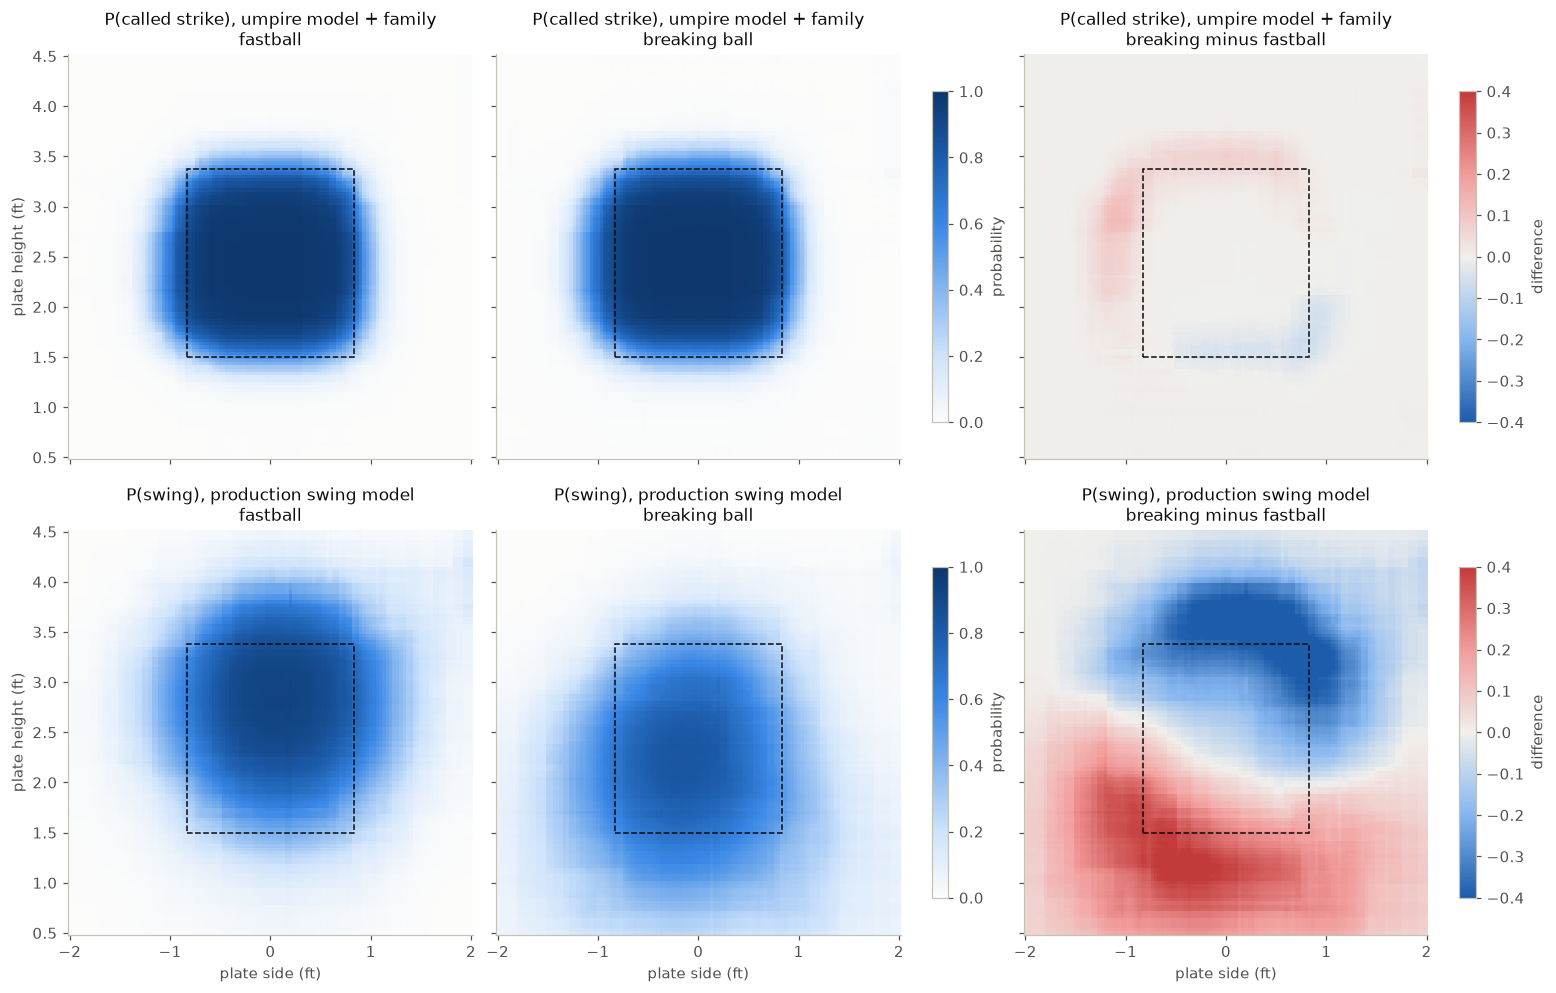

In [5]:
train_takes = (dec["2026"].filter(pl.col("is_verified"), ~pl.col("is_bunt"), pl.col("swung") == 0)
                          .select("PitchCall", *LOC, *FAM).to_pandas())
train_takes["PitchFamily"] = train_takes["PitchFamily"].astype("category")
ump_fam = lgb.LGBMClassifier(objective="binary", n_estimators=eye_v1.N_TREES["ump"], **eye_v1.LGB_PARAMS)
ump_fam.fit(train_takes[LOC + FAM], (train_takes["PitchCall"] == "StrikeCalled").astype(int))

xs, zs = np.linspace(-2, 2, 121), np.linspace(0.5, 4.5, 121)
XX, ZZ = np.meshgrid(xs, zs)


def surface(model, family, balls=1, strikes=1, side=0):
    grid = pd.DataFrame({"BatterSide": side, "Balls": balls, "Strikes": strikes,
                         "PlateLocHeight": ZZ.ravel(), "PlateLocSide": XX.ravel(),
                         "PitchFamily": pd.Categorical([family] * XX.size, categories=eye_v1.FAM_CATS)})
    return model.predict_proba(grid[LOC + FAM])[:, 1].reshape(XX.shape)


fig, axes = plt.subplots(2, 3, figsize=(14, 9), sharex=True, sharey=True, layout="constrained")
for row, (label, model) in zip(axes, [("P(called strike), umpire model + family", ump_fam),
                                      ("P(swing), production swing model", models["2026"].swing)]):
    fb, bb = surface(model, "Fastball"), surface(model, "Breaking")
    for ax, surf, title, cmap, lims in [(row[0], fb, "fastball", SEQ, (0, 1)),
                                        (row[1], bb, "breaking ball", SEQ, (0, 1)),
                                        (row[2], bb - fb, "breaking minus fastball", DIV, (-0.4, 0.4))]:
        im = ax.pcolormesh(xs, zs, surf, cmap=cmap, vmin=lims[0], vmax=lims[1], shading="auto")
        if ax is row[1]:
            fig.colorbar(im, ax=row[1], shrink=0.8, label="probability")
        ax.add_patch(Rectangle((-ZONE["h"], ZONE["b"]), 2 * ZONE["h"], ZONE["t"] - ZONE["b"],
                               fill=False, ec=INK, ls="--", lw=1))
        ax.set_title(f"{label}\n{title}")
        ax.set_aspect("equal")
    fig.colorbar(im, ax=row[2], shrink=0.8, label="difference")
    print(f"{label}: mean |breaking − fastball| over the plot = {np.abs(bb - fb).mean():.3f}, "
          f"largest = {np.abs(bb - fb).max():.2f}")
for ax in axes[:, 0]:
    ax.set_ylabel("plate height (ft)")
for ax in axes[1]:
    ax.set_xlabel("plate side (ft)")
plt.show()

The umpire's call barely depends on family. The difference panel stays within ±0.13, averages 0.010, and the only visible shading sits right on the zone's edges.

The swing surfaces are a different story. Hitters swing far more at breaking balls at and below the bottom of the zone, and far less at breaking balls up in the zone: differences up to 0.48, averaging 0.17. That's chasing and pitch recognition, and it's why family belongs in the swing model.

### 1c. Would adding family to the umpire model change anyone's eye?

Re-price every take with the family-aware umpire model and recompute eye, keeping the production swing and swing-value models. Compare each hitter overall, and split the way the hitter reports split (fastballs / breaking / offspeed; at least 75 pitches of that family).

In [6]:
s26 = S["2026"]
p_fam = ump_fam.predict_proba(s26.select(LOC + FAM).to_pandas())[:, 1]
s26 = (s26.with_columns(pl.Series("p_strike_fam", p_fam))
          .with_columns((pl.col("p_strike_fam") * pl.col("rv_strike")
                         + (1 - pl.col("p_strike_fam")) * pl.col("rv_ball")).alias("ev_take_fam"))
          .with_columns(((pl.col("swung") - pl.col("p_swing"))
                         * (pl.col("ev_swing") - pl.col("ev_take_fam"))).alias("eye_fam")))


def compare_split(s, family=None, min_n=MIN_N):
    if family:
        s = s.filter(pl.col("report_family") == family)
    h = (s.group_by("Batter").agg(pl.len().alias("n"), (pl.col("eye").mean() * 100).alias("shipped"),
                                  (pl.col("eye_fam").mean() * 100).alias("family_ump"))
          .filter(pl.col("n") >= min_n))
    diff = (h["shipped"] - h["family_ump"]).abs()
    return {"split": family or "all pitches", "hitters": h.height,
            "correlation": h.select(pl.corr("shipped", "family_ump")).item(),
            "average change per 100": diff.mean(), "largest change per 100": diff.max(),
            "spread of hitters (SD)": h["shipped"].std()}


display(pl.DataFrame([compare_split(s26)] + [compare_split(s26, f, 75) for f in ["Fastballs", "Breaking", "Offspeed"]]))

# the reports split on the tagged pitch type; the models use AutoPitchType's family
model_fam = pl.col("report_family").replace_strict({"Fastballs": "Fastball", "Breaking": "Breaking",
                                                    "Offspeed": "Offspeed"}, default="Other")
agree = s26.select((model_fam == pl.col("PitchFamily").cast(pl.Utf8)).mean()).item()
print(f"The report's family (tagged) matches the model's family (AutoPitchType) on {100 * agree:.1f}% of decisions.")

split,hitters,correlation,average change per 100,largest change per 100,spread of hitters (SD)
str,i64,f64,f64,f64,f64
"""all pitches""",3154,1.000,0.008,0.067,0.564
"""Fastballs""",3585,1.000,0.013,0.131,0.672
"""Breaking""",3012,1.000,0.014,0.079,0.848
"""Offspeed""",1170,1.000,0.020,0.098,0.913


The report's family (tagged) matches the model's family (AutoPitchType) on 90.0% of decisions.


Re-pricing every take with the family-aware umpire model changes the average hitter's Eye/100 by 0.008 per 100 (largest 0.07), against a 0.56 spread between hitters; the correlation rounds to 1.000. Inside the family splits the average change is 0.013–0.020 per 100, against spreads of 0.67–0.91. **The umpire-model choice has no visible effect on the hitter reports' family splits.**

One detail for the writeup: the reports split on the tagged pitch type (falling back to AutoPitchType), while the models use AutoPitchType's family. The two agree on 90% of decisions, so some pitches a report lists as breaking balls were priced by the models as another family, and vice versa.

### 1d. Does the family split carry real signal?

If Eye/100 vs breaking balls were just noise, it wouldn't repeat from one season to the next. Year-over-year correlation per family, for returning hitters with at least 100 pitches of that family in both seasons.

The last row asks the sharper question. A family split is only useful beyond overall eye if the *gap between families* is a trait too: does a hitter who is better against fastballs than breaking balls this season stay that way next season?

In [7]:
def per_hitter_family(s, family):
    return (s.filter(pl.col("report_family") == family)
             .group_by("Batter").agg(pl.len().alias("n"), (pl.col("eye").mean() * 100).alias("eye100")))


rows = []
for family in ["all pitches", "Fastballs", "Breaking", "Offspeed"]:
    HF = {y: H[y] if family == "all pitches" else per_hitter_family(S[y], family) for y in YEARS}
    P = pairs(HF, min_n=100)
    share = np.mean([S[y]["report_family"].eq(family).mean() for y in YEARS]) if family != "all pitches" else 1.0
    rows.append({"split": family, "share of decisions": 100 * share, "returning hitters": P.height,
                 "year-over-year r": yoy(P, "eye100"), "spread of hitters (SD per 100)": P["eye100"].std()})

# the within-hitter contrast: Eye/100 vs breaking minus Eye/100 vs fastballs (>= 100 of each, both seasons)
HC = {}
for y in YEARS:
    fb, bb = per_hitter_family(S[y], "Fastballs"), per_hitter_family(S[y], "Breaking")
    HC[y] = (fb.join(bb, on="Batter", suffix="_bb")
               .select("Batter", pl.min_horizontal("n", "n_bb").alias("n"),
                       (pl.col("eye100_bb") - pl.col("eye100")).alias("eye100")))
P = pairs(HC, min_n=100)
rows.append({"split": "breaking minus fastballs (same hitter)", "share of decisions": None,
             "returning hitters": P.height, "year-over-year r": yoy(P, "eye100"),
             "spread of hitters (SD per 100)": P["eye100"].std()})
pl.DataFrame(rows)

split,share of decisions,returning hitters,year-over-year r,spread of hitters (SD per 100)
str,f64,i64,f64,f64
"""all pitches""",100.000,6504,0.474,0.620
"""Fastballs""",55.801,4638,0.493,0.654
"""Breaking""",32.209,2929,0.445,0.832
"""Offspeed""",11.962,409,0.445,0.880
"""breaking minus fastballs (same…",null,2919,0.380,0.912


Each family split repeats about as well as overall eye at a similar sample size (r 0.45–0.49, vs 0.47), and hitters spread out more within a family (SD 0.65–0.88 per 100) than overall.

More importantly, **the gap between a hitter's breaking-ball eye and fastball eye repeats too (r = 0.38)**. A hitter who is relatively worse against breaking balls this season tends to stay that way next season. So the family split tells you something about a hitter that overall Eye/100 doesn't. It is noisier, though, because each split has fewer decisions (see 7e).

## 2. Eye vs chase % and good decision %

Definitions, the same as the app's batter table:

- **Chase %**: swings at pitches outside the zone ÷ pitches outside the zone.
- **Good decision %**: (swings at in-zone pitches + takes of out-of-zone pitches) ÷ all decisions.
- **Eye/100**: runs gained per 100 decisions versus the league's usual choice.

Good decision % is eye's closest simple cousin: both reward swinging at strikes and taking balls. Eye differs in three ways:

1. It uses the umpire's *likely* call instead of a hard box.
2. It weighs each decision by the runs at stake in that count.
3. It only gives credit for beating the league's usual choice.

All three stats are computed on eye's population (competitive decisions, bunts removed), so the denominators match. The app's Good Decision % divides by every pitch with a location, so its numbers differ slightly. Hitters need ≥200 decisions (in both seasons, for year-over-year).

### 2a. How related are they within a season? (2026)

In [8]:
METRICS = {"eye100": "Eye/100", "good_dec": "good decision %", "chase": "chase %", "zswing": "zone swing %",
           "bb": "walk %", "k": "strikeout %", "rv100": "RV/100"}
h26 = H["2026"].filter(pl.col("n") >= MIN_N)
corr = h26.select(list(METRICS)).corr()
corr.columns = list(METRICS.values())
corr.insert_column(0, pl.Series("metric", list(METRICS.values())))
corr

metric,Eye/100,good decision %,chase %,zone swing %,walk %,strikeout %,RV/100
str,f64,f64,f64,f64,f64,f64,f64
"""Eye/100""",1.000,0.652,-0.802,-0.240,0.562,-0.252,0.203
"""good decision %""",0.652,1.000,-0.565,0.373,0.341,-0.152,0.175
"""chase %""",-0.802,-0.565,1.000,0.549,-0.657,0.139,-0.163
"""zone swing %""",-0.240,0.373,0.549,1.000,-0.416,-0.002,-0.013
"""walk %""",0.562,0.341,-0.657,-0.416,1.000,-0.023,0.332
"""strikeout %""",-0.252,-0.152,0.139,-0.002,-0.023,1.000,-0.312
"""RV/100""",0.203,0.175,-0.163,-0.013,0.332,-0.312,1.000


### 2b. How stable is each one year over year?

In [9]:
P = pairs(H)
pair_names = P["pair"].unique(maintain_order=True).to_list()
pl.DataFrame([{"metric": label, **{p: yoy(P.filter(pl.col("pair") == p), col) for p in pair_names},
               "pooled": yoy(P, col)} for col, label in METRICS.items()])

metric,2022→2023,2023→2024,2024→2025,2025→2026,pooled
str,f64,f64,f64,f64,f64
"""Eye/100""",0.565,0.538,0.574,0.540,0.551
"""good decision %""",0.390,0.403,0.399,0.411,0.402
"""chase %""",0.624,0.578,0.604,0.620,0.606
"""zone swing %""",0.607,0.541,0.607,0.575,0.583
"""walk %""",0.419,0.381,0.362,0.390,0.383
"""strikeout %""",0.534,0.534,0.599,0.577,0.566
"""RV/100""",0.219,0.202,0.235,0.230,0.225


### 2c. Which one predicts next season best?

R² for a next-season result from this season's numbers (pooled returning hitters). The last column is the result predicting itself, for scale.

In [10]:
def r2(df, xs, y):
    X = np.column_stack([np.ones(df.height)] + [df[x].to_numpy() for x in xs])
    yv = df[y].to_numpy()
    ok = ~np.isnan(X).any(axis=1) & ~np.isnan(yv)
    resid = yv[ok] - X[ok] @ np.linalg.lstsq(X[ok], yv[ok], rcond=None)[0]
    return 1 - resid.var() / yv[ok].var()


PREDICTORS = {"chase %": ["chase"], "good dec %": ["good_dec"], "Eye/100": ["eye100"],
              "chase + good dec": ["chase", "good_dec"], "chase + good dec + Eye": ["chase", "good_dec", "eye100"]}
pl.DataFrame([{"next season's": METRICS[t], **{k: r2(P, v, t + "_next") for k, v in PREDICTORS.items()},
               "itself": r2(P, [t], t + "_next")} for t in ["bb", "k", "rv100", "eye100"]])

next season's,chase %,good dec %,Eye/100,chase + good dec,chase + good dec + Eye,itself
str,f64,f64,f64,f64,f64,f64
"""walk %""",0.140,0.036,0.101,0.142,0.146,0.147
"""strikeout %""",0.003,0.000,0.011,0.004,0.018,0.320
"""RV/100""",0.004,0.004,0.008,0.005,0.008,0.051
"""Eye/100""",0.269,0.126,0.304,0.271,0.324,0.304


**Result.**

- **Within a season**, eye tracks chase % (r = −0.80) more closely than good decision % (0.65). Good decision % rewards zone swings (+0.37 with zone swing %); eye leans slightly the other way (−0.24), because swinging at a pitch just inside the box is often not the better play (2e).
- **Stability:** eye repeats at r = 0.55, well above good decision % (0.40) and walk % (0.38), and a little below chase % (0.61) and zone swing % (0.58).
- **Prediction:** for next season's walk %, chase % does best (R² 0.140, vs 0.101 for eye and 0.036 for good decision %). For next season's strikeout % and RV/100, eye does best of the three (0.011 and 0.008, vs at most 0.004). All of these are small. RV/100 is so noisy that last season's RV/100 only reaches 0.051, so eye gets about a sixth of the way there from decisions alone. Adding eye to chase % + good decision % raises every R².
- **Next season's eye** is predicted better by this season's eye (0.304) than by chase % and good decision % together (0.271).

**For the writeup:** eye isn't a separate dimension from plate discipline; it's plate discipline measured in runs. It beats good decision % on every test. Against chase % it's a trade-off. Chase % is the steadier rate and the better walk predictor. Eye is in runs, weighs each decision by what was at stake, and predicts strikeouts and run value slightly better.

### 2d. Where eye and good decision % disagree

Fit a straight line from good decision % to Eye/100, then look at the hitters furthest above and below it. The last three columns split each hitter's Eye/100 into the part earned in **2-strike or 3-ball counts** and the part earned in every other count (the two add up to Eye/100).

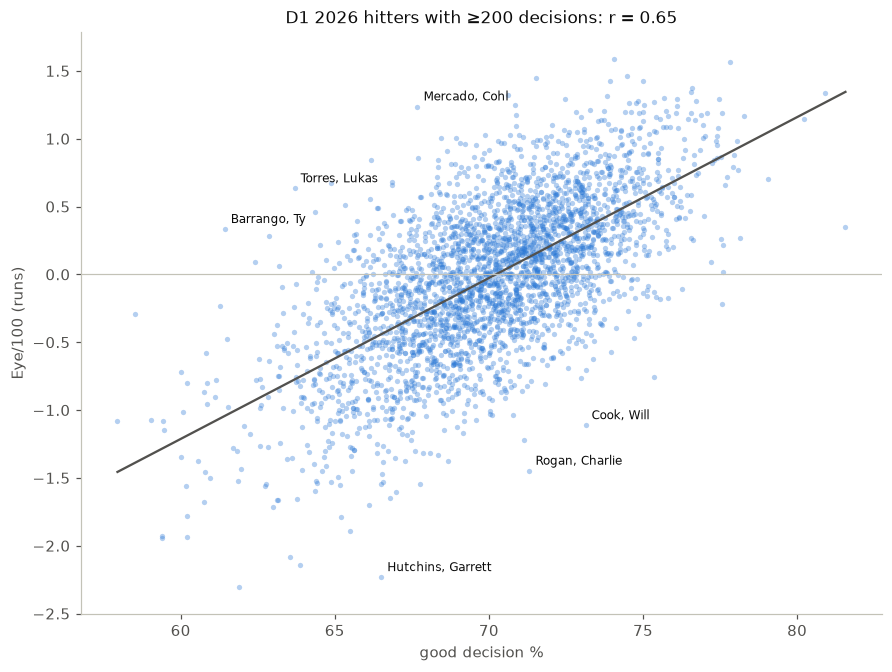

Batter,n,good_dec,chase,eye100,eye vs line,% in 2-strike/3-ball,eye from 2-strike/3-ball,eye from other counts
str,u32,f64,f64,f64,f64,f64,f64,f64
"""Mercado, Cohl""",328,0.677,0.151,1.237,1.538,36.585,0.671,0.566
"""Torres, Lukas""",314,0.637,0.225,0.633,1.408,34.395,0.455,0.178
"""Barrango, Ty""",770,0.614,0.163,0.334,1.377,36.753,0.347,-0.013
"""DeSarno, Patrick""",278,0.662,0.248,0.845,1.324,27.698,0.455,0.390
"""Gasser, Camden""",444,0.649,0.083,0.675,1.310,36.937,0.679,-0.005
"""— average hitter —""",563,0.701,0.268,-0.016,-0.000,30.957,-0.009,-0.007
"""Hutchins, Garrett""",206,0.665,0.444,-2.232,-1.791,28.641,-0.866,-1.366
"""Rogan, Charlie""",495,0.713,0.357,-1.448,-1.577,31.919,-0.933,-0.515
"""Cook, Will""",201,0.731,0.295,-1.113,-1.458,34.328,-1.192,0.079


In [11]:
LEVERAGE = (pl.col("Strikes") == 2) | (pl.col("Balls") == 3)
lev = S["2026"].group_by("Batter").agg(
    (100 * LEVERAGE.mean()).alias("% in 2-strike/3-ball"),
    (pl.col("eye").filter(LEVERAGE).sum() / pl.len() * 100).alias("eye from 2-strike/3-ball"),
    (pl.col("eye").filter(~LEVERAGE).sum() / pl.len() * 100).alias("eye from other counts"))
slope, intercept = np.polyfit(h26["good_dec"], h26["eye100"], 1)
d2 = (h26.with_columns((pl.col("eye100") - slope * pl.col("good_dec") - intercept).alias("eye vs line"))
         .join(lev, on="Batter"))

fig, ax = plt.subplots(figsize=(8, 6), layout="constrained")
ax.scatter(d2["good_dec"] * 100, d2["eye100"], s=12, color=BLUE, alpha=0.35, linewidths=0)
gx = np.linspace(d2["good_dec"].min(), d2["good_dec"].max(), 50)
ax.plot(gx * 100, slope * gx + intercept, color=MUTED, lw=1.5)
for r in pl.concat([d2.sort("eye vs line").head(3), d2.sort("eye vs line").tail(3)]).iter_rows(named=True):
    ax.annotate(r["Batter"], (r["good_dec"] * 100, r["eye100"]), xytext=(4, 4), textcoords="offset points",
                fontsize=8, color=INK)
ax.axhline(0, color="#c3c2b7", lw=0.8)
ax.set_xlabel("good decision %")
ax.set_ylabel("Eye/100 (runs)")
ax.set_title(f"D1 2026 hitters with ≥{MIN_N} decisions: r = {h26.select(pl.corr('good_dec', 'eye100')).item():.2f}")
plt.show()

cols = ["Batter", "n", "good_dec", "chase", "eye100", "eye vs line", "% in 2-strike/3-ball",
        "eye from 2-strike/3-ball", "eye from other counts"]
league = d2.select(pl.lit("— average hitter —").alias("Batter"), pl.col("n").mean().round(0).cast(pl.UInt32),
                   *[pl.col(c).mean() for c in cols[2:]])
pl.concat([d2.sort("eye vs line", descending=True).head(5).select(cols), league.select(cols),
           d2.sort("eye vs line").head(5).select(cols)], how="vertical_relaxed")

Two patterns stand out:

- **Eye weighs decisions by what was at stake; good decision % counts them all the same.** Barrango and Gasser have below-average good decision % but earn about +0.35 and +0.68 per 100 in 2-strike/3-ball counts, and nothing elsewhere. Cook has an above-average good decision % (73%) but loses 1.19 per 100 in those counts.
- **Good decision % rewards swinging at anything in the box.** Rogan (71%) and Dalley (75%) are above average on good decision % with chase rates over 30%. Their swings at pitches just inside the box count as good decisions but earn little eye (2e), while their chases cost eye in full.

### 2e. Why they disagree: the box vs. the run values

Good decision % says *swing* at every pitch inside the box and *take* every pitch outside it. Eye says swing where an average hitter's swing is worth more than the take (`ev_swing > ev_take`). The table groups 2026 decisions by how far the pitch is from the nearest edge of the box (inches; negative = outside), and shows how often swinging is actually the better play.

In [12]:
edge_in = 12 * pl.min_horizontal(ZONE["h"] - pl.col("PlateLocSide").abs(),       # inches inside the box (negative = outside)
                                 pl.col("PlateLocHeight") - ZONE["b"], ZONE["t"] - pl.col("PlateLocHeight"))
BANDS = [(-99, -6, "6+ in outside"), (-6, -3, "3–6 in outside"), (-3, 0, "0–3 in outside"),
         (0, 3, "0–3 in inside"), (3, 6, "3–6 in inside"), (6, 99, "6+ in inside")]
band = pl.lit(None, dtype=pl.Utf8)
for lo, hi, label in BANDS:
    band = pl.when(edge_in.is_between(lo, hi, closed="left")).then(pl.lit(label)).otherwise(band)
better = (pl.col("ev_swing") > pl.col("ev_take"))
(S["2026"].with_columns(band.alias("distance from the box edge"), edge_in.alias("_d"))
          .group_by("distance from the box edge")
          .agg(pl.len().alias("decisions"), pl.col("_d").mean().alias("_order"),
               pl.when(pl.col("_d") >= 0).then(pl.lit("swing")).otherwise(pl.lit("take")).first().alias("box says"),
               (100 * better.mean()).alias("swing is better, % (all counts)"),
               (100 * better.filter(pl.col("Strikes") < 2).mean()).alias("… 0-1 strikes"),
               (100 * better.filter(pl.col("Strikes") == 2).mean()).alias("… 2 strikes"),
               (100 * pl.col("p_swing").mean()).alias("league swing %"),
               (pl.col("ev_swing") - pl.col("ev_take")).abs().mean().alias("avg |swing − take| (runs)"))
          .sort("_order").drop("_order"))

distance from the box edge,decisions,box says,"swing is better, % (all counts)",… 0-1 strikes,… 2 strikes,league swing %,avg |swing − take| (runs)
str,u32,str,f64,f64,f64,f64,f64
"""6+ in outside""",498925,"""take""",0.000,0.000,0.000,12.520,0.230
"""3–6 in outside""",265184,"""take""",1.041,0.000,3.795,31.103,0.183
"""0–3 in outside""",326107,"""take""",14.299,6.311,37.412,44.620,0.103
"""0–3 in inside""",346786,"""swing""",69.966,61.679,95.587,58.195,0.074
"""3–6 in inside""",303735,"""swing""",94.843,93.260,100.000,68.831,0.117
"""6+ in inside""",203885,"""swing""",97.003,96.121,100.000,75.119,0.140


Away from the edges, the box and the run values agree. Near the edges they don't:

- For pitches **0–3 inches inside** the box, swinging is the better play only 70% of the time (62% with fewer than two strikes).
- For pitches **0–3 inches outside**, it's the better play 14% of the time (37% with two strikes, when protecting the plate pays).

That edge band is about a third of all decisions (673k of 1.94M), and it's where good decision % and eye part ways. It's also where the stakes are smallest: 0.07–0.10 runs between swinging and taking, vs 0.14–0.23 far from the edge. That's the other reason eye barely rewards swinging at borderline strikes.

## 3. Team decisions: bunts and 3-0 counts

### 3a. Bunts are removed

A bunt is usually a call from the dugout, not a read of the pitch. The shipped model scores a bunt as a swing, so a sacrifice bunt at a pitch off the plate is debited as a chase. Bunts also feed the swing-value model, dragging down the value of swinging in the spots where teams bunt.

Everything in this notebook already has bunts removed from both training and scoring. The comparison below is against the shipped scores (`pipeline_v2/artifacts/eyescore_D1_{year}.parquet`), which still include them.

**Limitation (for the writeup):** only bunts put in play are tagged (`TaggedHitType == "Bunt"`). A bunt that is fouled off or missed is recorded as `FoulBall…` or `StrikeSwinging` with no hit type, so those attempts stay in.

In [13]:
SHIPPED = {y: pl.read_parquet(ARTIFACTS / f"eyescore_D1_{y}.parquet").rename({"eye": "eye_shipped"}) for y in YEARS}
rows = []
for y in YEARS:
    inplay = dec[y].filter(pl.col("PitchCall") == "InPlay").join(SHIPPED[y], on="PitchUID", how="left")
    bunts = inplay.filter(pl.col("is_bunt"))
    rows.append({"season": y, "bunts": bunts.height, "% of balls in play": 100 * bunts.height / inplay.height,
                 "shipped eye on bunts (runs)": bunts["eye_shipped"].sum(),
                 "per bunt": bunts["eye_shipped"].mean(),
                 "per other ball in play": inplay.filter(~pl.col("is_bunt"))["eye_shipped"].mean()})
with pl.Config(float_precision=4):
    display(pl.DataFrame(rows))

# who it moves: the season's most frequent bunters, shipped vs bunts removed
y = "2026"
shipped_h = (dec[y].join(SHIPPED[y], on="PitchUID", how="inner")
                   .group_by("Batter").agg(pl.col("is_bunt").sum().alias("bunts"),
                                           (pl.col("eye_shipped").mean() * 100).alias("Eye/100 shipped")))
moved = (shipped_h.join(H[y].select("Batter", "n", pl.col("eye100").alias("Eye/100 no bunts")), on="Batter")
                  .with_columns((pl.col("Eye/100 no bunts") - pl.col("Eye/100 shipped")).alias("change")))
both = moved.filter(pl.col("n") >= MIN_N)
print(f"2026 hitters with ≥{MIN_N} decisions: shipped vs no-bunts correlation "
      f"{both.select(pl.corr('Eye/100 shipped', 'Eye/100 no bunts')).item():.3f}, "
      f"average |change| {both['change'].abs().mean():.3f} per 100")
moved.sort("bunts", descending=True).head(10)

season,bunts,% of balls in play,shipped eye on bunts (runs),per bunt,per other ball in play
str,i64,f64,f64,f64,f64
"""2022""",3838,2.6352,-43.0632,-0.0112,0.0004
"""2023""",5379,2.7394,-71.0651,-0.0132,0.0001
"""2024""",7070,2.8208,-97.1798,-0.0137,0.0002
"""2025""",9147,2.9928,-117.0323,-0.0128,0.0007
"""2026""",10228,2.9588,-135.9421,-0.0133,0.0016


2026 hitters with ≥200 decisions: shipped vs no-bunts correlation 0.999, average |change| 0.019 per 100


Batter,bunts,Eye/100 shipped,n,Eye/100 no bunts,change
str,u32,f32,u32,f64,f64
"""Dierks, Marcus""",27,0.162,737,0.246,0.085
"""Barthol, Blake""",26,0.406,991,0.459,0.053
"""Johnson, Rett""",24,0.865,1691,0.880,0.015
"""Pridgen, Paris""",23,-0.690,753,-0.640,0.050
"""Beverley, John""",22,-0.396,729,-0.386,0.010
"""Cole, Christopher""",22,0.262,656,0.264,0.002
"""Gierer, Daniel""",22,-0.671,600,-0.646,0.025
"""Hallmark, Christian""",22,-0.118,678,-0.093,0.025
"""Rodriguez, Blaze""",20,0.173,1038,0.195,0.022


Bunts are 2.6–3.0% of balls in play each season, and the shipped model charged them 43–136 runs a season: −0.011 to −0.014 runs per bunt, against roughly zero for other balls in play.

For most hitters, removing bunts changes little (correlation 0.999, average change 0.02 per 100). But the change only goes one way, and it lands on the hitters who bunt: the most frequent bunters gain up to +0.085 per 100. Removing bunts also takes their outcomes out of the swing-value model's training data.

### 3b. 3-0 counts

On 3-0 the hitter is often under a take sign, so a take there is the dugout's decision too. A swing on 3-0 is the hitter's decision, but only after the dugout gives a green light. Three versions:

1. **All decisions**: the bunts-removed model above.
2. **3-0 takes removed**: what was asked for. Only the take signs drop out.
3. **Every 3-0 decision removed**: swings too.

The models stay the same in all three (they still learn from 3-0 pitches); only the hitter totals leave decisions out.

Why show version 3: removing only the takes is lopsided. A 3-0 take scores −P(swing) × (swing value − take value), and the league rarely swings on 3-0, so takes score close to zero anyway. A 3-0 swing keeps the full (1 − P(swing)) × (swing value − take value). Version 2 therefore still scores every green-light swing, and the green light is also a team decision.

First, what 3-0 looks like:

In [14]:
IS_30 = (pl.col("Balls") == 3) & (pl.col("Strikes") == 0)
s = S["2026"]
t30 = s.filter(IS_30)
print(f"3-0 is {100 * t30.height / s.height:.1f}% of decisions. Hitters swing at {100 * t30['swung'].mean():.1f}% "
      f"of 3-0 pitches ({100 * t30.filter(pl.col('in_zone'))['swung'].mean():.1f}% of 3-0 strikes).")
(t30.group_by(pl.when(pl.col("swung") == 1).then(pl.lit("3-0 swing")).otherwise(pl.lit("3-0 take")).alias("decision"))
    .agg(pl.len().alias("decisions"), pl.col("eye").mean().alias("eye per decision"),
         pl.col("eye").sum().alias("total eye (runs)"),
         pl.col("eye").abs().sum().alias("total |eye| (runs)"))
    .with_columns((100 * pl.col("total |eye| (runs)") / s["eye"].abs().sum()).alias("% of all |eye|"))
    .sort("decision"))

3-0 is 1.5% of decisions. Hitters swing at 4.4% of 3-0 pitches (6.8% of 3-0 strikes).


decision,decisions,eye per decision,total eye (runs),total |eye| (runs),% of all |eye|
str,u32,f64,f64,f64,f64
"""3-0 swing""",1271,-0.069,-87.415,87.571,0.119
"""3-0 take""",27864,0.004,105.032,105.083,0.143


In [15]:
VARIANTS = {"all decisions": None,
            "3-0 takes removed": IS_30 & (pl.col("swung") == 0),
            "every 3-0 decision removed": IS_30}
HV = {name: {y: per_hitter(S[y], drop).join(OUT[y], on="Batter", how="left") for y in YEARS}
      for name, drop in VARIANTS.items()}
base = HV["all decisions"]["2026"].filter(pl.col("n") >= MIN_N).select("Batter", pl.col("eye100").alias("base"))
rows = []
for name, Hv in HV.items():
    Pv = pairs(Hv)
    h = Hv["2026"].join(base, on="Batter")
    rows.append({"version": name, "correlation with all decisions (2026)": h.select(pl.corr("eye100", "base")).item(),
                 "average |change| per 100": (h["eye100"] - h["base"]).abs().mean(),
                 "year-over-year r": yoy(Pv, "eye100"),
                 "R² next-season walk %": r2(Pv, ["eye100"], "bb_next"),
                 "R² next-season RV/100": r2(Pv, ["eye100"], "rv100_next")})
display(pl.DataFrame(rows))

swing30 = (S["2026"].filter(IS_30).group_by("Batter")
                    .agg(pl.len().alias("3-0 decisions"), (100 * pl.col("swung").mean()).alias("3-0 swing %")))
movers = (base.join(HV["3-0 takes removed"]["2026"].select("Batter", pl.col("eye100").alias("3-0 takes removed")), on="Batter")
              .join(HV["every 3-0 decision removed"]["2026"].select("Batter", pl.col("eye100").alias("all 3-0 removed")), on="Batter")
              .join(swing30, on="Batter")
              .rename({"base": "all decisions"})
              .with_columns((pl.col("all 3-0 removed") - pl.col("all decisions")).alias("change")))
pl.concat([movers.sort("change").head(5), movers.sort("change").tail(5)])

version,correlation with all decisions (2026),average |change| per 100,year-over-year r,R² next-season walk %,R² next-season RV/100
str,f64,f64,f64,f64,f64
"""all decisions""",1.000,0.000,0.551,0.101,0.008
"""3-0 takes removed""",1.000,0.007,0.553,0.103,0.008
"""every 3-0 decision removed""",1.000,0.010,0.551,0.103,0.008


Batter,all decisions,3-0 takes removed,all 3-0 removed,3-0 decisions,3-0 swing %,change
str,f64,f64,f64,u32,f64,f64
"""Clayton, Elijah""",-1.663,-1.720,-1.720,9,0.000,-0.057
"""Martinez, Carlos""",-1.697,-1.748,-1.748,7,0.000,-0.051
"""Speirs, Gavin""",-1.933,-1.981,-1.981,8,0.000,-0.048
"""Reese, Ripken""",-1.249,-1.295,-1.295,17,0.000,-0.046
"""Barile, Garrison""",-1.167,-1.210,-1.210,10,0.000,-0.043
"""Baker, George""",-0.491,-0.507,-0.386,6,16.667,0.106
"""McAllister, Levi""",-0.495,-0.498,-0.380,2,50.000,0.115
"""Gibson, Michael""",0.183,0.181,0.303,13,15.385,0.120
"""Payton, Colten""",-0.470,-0.476,-0.325,5,60.000,0.145


**Result.**

- 3-0 is 1.5% of decisions and about 0.26% of all eye (in absolute runs). Hitters swing at only 4.4% of 3-0 pitches (6.8% of 3-0 strikes). So the swing model already expects a take, and a 3-0 take earns almost nothing (+0.004 runs).
- A 3-0 swing **costs** 0.069 runs on average: outside the heart of the plate, taking with a walk this close is worth more than swinging.
- Removing 3-0 takes moves hitters by 0.007 per 100 on average. The largest moves (about −0.05) are hitters who took every 3-0 pitch and lose that small credit.
- Removing every 3-0 decision moves hitters by 0.010 on average. The largest moves (+0.10 to +0.15) are green-light hitters whose 3-0 swings stop counting against them.
- Year-over-year r and next-season prediction are unchanged in every version.

**Conclusion:** take signs are a real team decision, but they don't distort eye. The writeup can report results with 3-0 takes removed (version 2) and note that removing every 3-0 decision gives the same picture.

## 4. Limitation: swing value only learns from swings that happened

The swing-value model is trained on swings, so EV(swing) at a spot means "what happened when *someone chose* to swing there". That's the right number where most hitters swing. Where almost nobody swings, the few who do are self-selected: green-lit hitters on 3-0, or hitters who read that pitch well. Their results are better than an average hitter's would be, so:

- **chases look cheaper than they are**: the swings at pitches far off the plate come from the hitters who make those swings work;
- **3-0 aggression looks better than it is**: 3-0 swings mostly come from the hitters trusted to take them.

The model can't see this, because the trait that drives the choice (who the hitter is, what they saw) isn't a feature. Removing it would need either hitter quality in the swing-value model (which would let the bat back into eye) or a selection model. For v1 it is a stated limitation.

**Evidence.** Give each hitter a bat-quality score: their average run value per ball in play, outside 3-0 counts (≥30 balls in play), as a percentile among hitters. Then compare the hitters who *see* a type of pitch with the hitters who *swing* at it. If those groups match, the swings are representative; if the swingers are better hitters, EV(swing) is learned from better bats than the average hitter brings.

In [16]:
s = S["2026"]
bat = (s.filter(pl.col("PitchCall") == "InPlay", ~IS_30, pl.col("run_value").is_not_null())
        .group_by("Batter").agg(pl.len().alias("bip"), pl.col("run_value").mean().alias("bat"))
        .filter(pl.col("bip") >= 30)
        .with_columns((100 * pl.col("bat").rank() / pl.len()).alias("bat percentile")))
sb = s.join(bat.select("Batter", "bat percentile"), on="Batter", how="inner")
SITUATIONS = {"every decision": pl.lit(True),
              "3-0 counts": IS_30,
              "pitches the league rarely swings at (P(swing) < 10%)": pl.col("p_swing") < 0.10,
              "pitches the league usually swings at (P(swing) > 70%)": pl.col("p_swing") > 0.70}
rows = []
for name, cond in SITUATIONS.items():
    seen = sb.filter(cond)
    swung = seen.filter(pl.col("swung") == 1)
    rows.append({"pitches": name, "decisions": seen.height, "swings": swung.height,
                 "swing %": 100 * swung.height / seen.height,
                 "bat percentile, hitters who saw them": seen["bat percentile"].mean(),
                 "bat percentile, hitters who swung": swung["bat percentile"].mean()})
pl.DataFrame(rows).with_columns((pl.col("bat percentile, hitters who swung")
                                 - pl.col("bat percentile, hitters who saw them")).alias("gap"))

pitches,decisions,swings,swing %,"bat percentile, hitters who saw them","bat percentile, hitters who swung",gap
str,i64,i64,f64,f64,f64,f64
"""every decision""",1773735,781328,44.050,54.147,54.637,0.491
"""3-0 counts""",26770,1197,4.471,53.713,61.733,8.020
"""pitches the league rarely swin…",335861,12597,3.751,54.069,55.842,1.772
"""pitches the league usually swi…",433750,365867,84.350,54.148,54.275,0.127


**Result.** On 3-0, the hitters who swing are clearly better bats than the hitters who see 3-0 pitches: 61.7th vs 53.7th percentile, an 8-point gap. That's the green light at work, and it means EV(swing) on 3-0 is learned from better hitters than average.

On pitches the league rarely swings at, the gap is small (1.8 points): chase swings come from roughly the same hitters who see those pitches. Where the league usually swings there's no gap (0.1). So the selection problem is real but concentrated on 3-0, which is only 1.5% of decisions (3b).

(The "saw them" column sits above 50 because it's weighted by pitches: everyday players see more pitches and are better hitters.)

## 5. Note on future development: pitch quality

The swing model and the swing-value model know a pitch's location, count and family, but not how good it was. A 95 mph fastball with ride and an 86 mph flat one in the same spot get the same P(swing) and the same EV(swing). The same goes for a sharp slider and a hanging one.

What that does to eye:

- **Strength of schedule.** Hitters who face better stuff chase more than the league baseline expects and get debited for it, even when their decisions are ordinary *for the pitches they saw*. The review found conference averages from −0.23 per 100 (ASUN) to +0.10 (A10, SOCON), not explained by umpire zones. Pitch quality is a likely contributor.
- **The baseline is blurrier than it needs to be.** "What the league does with this pitch" is really "what the league does with an average pitch of this family in this spot".

**v2:** add pitch quality to the swing and swing-value models: velocity and movement (induced vertical break, horizontal break, perhaps release height and extension), or the pitch's Stuff+ once that model is settled. Keep it out of the umpire model; the call should still depend on location only. Re-check section 1's held-out losses, the year-over-year r, and the conference spread with and without it.

## 7. Why the app's raw Eye/100 needs shrinking

### The idea

A hitter's observed Eye/100 is **true skill + noise**. The noise is large because a single decision's score swings a lot: one taken 3-2 strike is −0.4 runs, and most decisions are worth almost nothing. Averaging over n decisions cuts the noise, but slowly.

Two variances describe it:

- **σ² (noise):** how much one decision's eye varies around the hitter's own average. The noise in an n-decision average is σ²/n.
- **τ² (skill):** how much true Eye differs between hitters.

The share of the observed spread that is real skill is the **reliability**:

$$\text{reliability}(n) = \frac{\tau^2}{\tau^2 + \sigma^2/n} = \frac{n}{n + K}, \qquad K = \frac{\sigma^2}{\tau^2}$$

**K is the number of decisions at which a hitter's number is half skill, half noise.** The best estimate of a hitter's true Eye/100 pulls the raw number toward the league average by exactly that share:

$$\text{shrunk} = \text{league avg} + \frac{n}{n+K}\,(\text{raw} - \text{league avg})$$

This is empirical Bayes shrinkage, the same "regression to the mean" baseball analysts use for any rate stat. A 600-decision regular barely moves; a 120-decision bench bat moves a lot. Shrinking doesn't change who is good; it stops small samples from topping the leaderboard by luck.

Everything depends on K, so the rest of this section estimates it two ways and checks which one the data agrees with.

### 7a. K from individual decisions (the `eye_v1.ipynb` method)

The method of moments (one-way random effects): the observed spread between hitters' averages, minus the spread that per-decision noise alone would create, is τ².

**A small correction:** `eye_v1.ipynb` used the *total* variance of every decision for σ². That includes the between-hitter spread, so it is slightly too big. The right σ² is the *within-hitter* variance. Both are shown; the difference is about 1%.

In [17]:
def estimate_K(s, by="Batter"):
    """One-way random-effects method of moments on per-decision eye."""
    g = s.group_by(by).agg(pl.len().alias("n"), pl.col("eye").mean().alias("m"), pl.col("eye").var().alias("v"))
    N, n_tot, mu = g.height, g["n"].sum(), s["eye"].mean()
    between = (g["n"] * (g["m"] - mu) ** 2).sum()
    denom = n_tot - (g["n"] ** 2).sum() / n_tot
    within = ((g["n"] - 1) * g["v"].fill_null(0.0)).sum() / (n_tot - N)    # pooled within-hitter variance
    total = s["eye"].var()
    tau2 = lambda sigma2: max((between - (N - 1) * sigma2) / denom, 1e-12)
    return {"league avg per 100": 100 * mu, "noise SD per decision": within ** 0.5,
            "skill SD per 100": 100 * tau2(within) ** 0.5,
            "K (v1: total variance)": total / tau2(total), "K (within-hitter variance)": within / tau2(within)}


KT = pl.DataFrame([{"season": y, **estimate_K(S[y])} for y in YEARS])
K_DECISION = dict(zip(KT["season"], KT["K (within-hitter variance)"]))
MU = dict(zip(KT["season"], KT["league avg per 100"]))
KT

season,league avg per 100,noise SD per decision,skill SD per 100,K (v1: total variance),K (within-hitter variance)
str,f64,f64,f64,f64,f64
"""2022""",0.004,0.060,0.492,151.439,149.512
"""2023""",0.007,0.064,0.486,174.656,172.836
"""2024""",0.005,0.065,0.504,169.859,168.208
"""2025""",0.002,0.065,0.486,179.021,177.436
"""2026""",0.002,0.065,0.480,186.792,185.239


### 7b. Checking K against the data: split halves

If K is right, it predicts how well a hitter's number in one half of their games matches the other half. Each 2026 game goes randomly to half A or half B. For hitters grouped by decisions per half, compare the observed A-vs-B correlation with the one K predicts, √(rel_A × rel_B).

The same halves give a second estimate of K that makes fewer assumptions:

- **Noise:** a hitter's two halves differ only by noise, so how far apart they are, scaled by their sample sizes, measures σ². (Precisely: E[(A − B)²] = σ²(1/n_A + 1/n_B).)
- **Skill:** across hitters, the covariance of half A with half B is τ², because the noise in the two halves is independent and only true skill is shared.

Whole games are split, so anything shared within a game (the same pitcher, the same umpire, the sequence of one at-bat) stays on one side. The per-decision method in 7a treats every decision as independent, which those shared conditions violate. The game-halves estimate is the median over 10 random splits (hitters need ≥25 decisions in each half).

season,K per decision (7a),K game halves
str,f64,f64
"""2022""",149.512,189.108
"""2023""",172.836,205.526
"""2024""",168.208,224.297
"""2025""",177.436,225.706
"""2026""",185.239,222.677


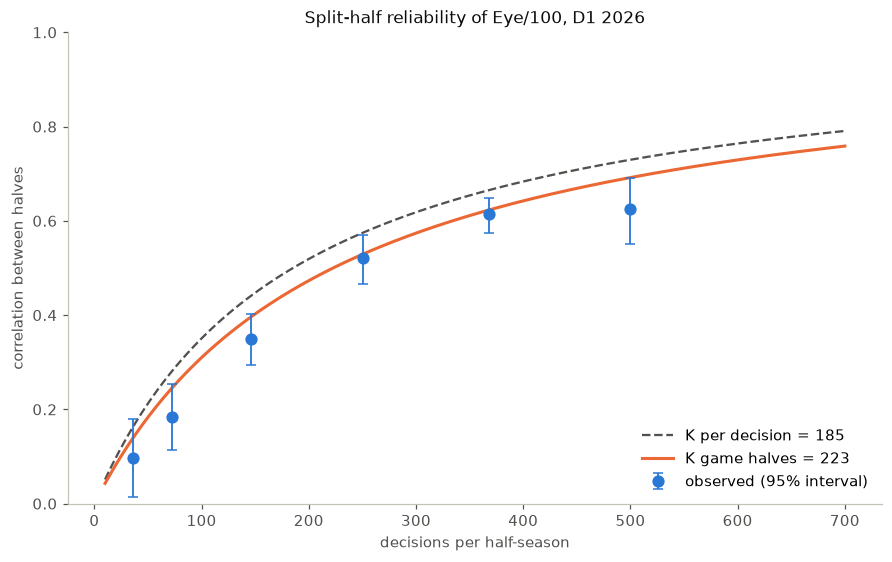

decisions per half,hitters,avg per half,observed r,"predicted, K per decision","predicted, K game halves"
str,u32,f64,f64,f64,f64
"""25–50""",558,36.073,0.097,0.148,0.127
"""50–100""",718,72.795,0.185,0.268,0.234
"""100–200""",1008,146.360,0.350,0.428,0.385
"""200–300""",766,250.228,0.520,0.566,0.521
"""300–450""",1085,368.334,0.614,0.659,0.617
"""450–700""",292,499.265,0.626,0.725,0.687


In [18]:
def halves(s, seed):
    """Per hitter: decisions and mean eye (per decision) in each random half of their games."""
    h = s.with_columns((pl.col("GameUID").hash(seed=seed) % 2).alias("half"))
    A = h.filter(pl.col("half") == 0).group_by("Batter").agg(pl.len().alias("nA"), pl.col("eye").mean().alias("eA"))
    B = h.filter(pl.col("half") == 1).group_by("Batter").agg(pl.len().alias("nB"), pl.col("eye").mean().alias("eB"))
    return A.join(B, on="Batter")


def k_game_halves(s, seeds=range(10), min_half=25):
    """K = noise / skill, both read off random game halves (median over several splits)."""
    ks = []
    for seed in seeds:
        x = halves(s, seed).filter(pl.col("nA") >= min_half, pl.col("nB") >= min_half)
        noise = ((x["eA"] - x["eB"]) ** 2).sum() / (1 / x["nA"] + 1 / x["nB"]).sum()
        skill = np.cov(x["eA"].to_numpy(), x["eB"].to_numpy())[0, 1]
        ks.append(noise / skill)
    return float(np.median(ks))


K = {y: k_game_halves(S[y]) for y in YEARS}
display(pl.DataFrame({"season": YEARS, "K per decision (7a)": [K_DECISION[y] for y in YEARS],
                      "K game halves": [K[y] for y in YEARS]}))

# observed split-half correlation by sample size (one split), against both predictions
sh = halves(S["2026"], seed=7).with_columns(((pl.col("nA") + pl.col("nB")) / 2).alias("per half"))
EDGES = [25, 50, 100, 200, 300, 450, 700]
bin_of = pl.lit(None, dtype=pl.Utf8)
for lo, hi in zip(EDGES[:-1], EDGES[1:]):
    bin_of = pl.when(pl.col("per half").is_between(lo, hi, closed="left")).then(pl.lit(f"{lo}–{hi}")).otherwise(bin_of)
pred = lambda k: ((pl.col("nA") / (pl.col("nA") + k)) * (pl.col("nB") / (pl.col("nB") + k))).sqrt()
split = (sh.with_columns(bin_of.alias("decisions per half")).drop_nulls("decisions per half")
           .group_by("decisions per half").agg(pl.len().alias("hitters"), pl.col("per half").mean().alias("avg per half"),
                                              pl.corr("eA", "eB").alias("observed r"),
                                              pred(K_DECISION["2026"]).mean().alias("predicted, K per decision"),
                                              pred(K["2026"]).mean().alias("predicted, K game halves"))
           .sort("avg per half"))
r_obs = split["observed r"].to_numpy()
z, se = np.arctanh(r_obs), 1 / np.sqrt(split["hitters"].to_numpy() - 3)

fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
m = np.linspace(10, 700, 200)
ax.plot(m, m / (m + K_DECISION["2026"]), color=MUTED, lw=1.5, ls="--", label=f"K per decision = {K_DECISION['2026']:.0f}")
ax.plot(m, m / (m + K["2026"]), color=ORANGE, lw=2, label=f"K game halves = {K['2026']:.0f}")
ax.errorbar(split["avg per half"].to_numpy(), r_obs,
            yerr=[r_obs - np.tanh(z - 1.96 * se), np.tanh(z + 1.96 * se) - r_obs],
            fmt="o", ms=7, color=BLUE, ecolor=BLUE, elinewidth=1.2, capsize=3, label="observed (95% interval)")
ax.set_xlabel("decisions per half-season")
ax.set_ylabel("correlation between halves")
ax.set_ylim(0, 1)
ax.legend(frameon=False, loc="lower right")
ax.set_title("Split-half reliability of Eye/100, D1 2026")
plt.show()
split

**Result.**

- The per-decision K (185) predicts more agreement between halves than the data shows, in every group.
- The game-halves K (223 for 2026; 189–226 across seasons) matches the regulars almost exactly: 200–450 decisions per half, observed 0.520 and 0.614 vs predicted 0.521 and 0.617.
- The smallest and largest groups sit below both curves. Playing time follows ability, so within a narrow band of playing time hitters are more alike than across the whole league, and that lowers a correlation measured inside the band. The game-halves estimate doesn't bin hitters, so it isn't affected.

**Why the per-decision method comes out low:** it treats every decision as independent. Decisions in the same game share a pitcher, an umpire and the at-bats they belong to, so a hitter's average is noisier than that formula assumes, and K comes out about 20% too small. **Use the game-halves K.** The rest of this section does.

### 7c. What K means for a given sample size (2026, game-halves K)

In [19]:
rel = pl.col("decisions") / (pl.col("decisions") + K["2026"])
pl.DataFrame({"decisions": [50, 100, 200, 300, 500, 800, 1200]}).with_columns(
    rel.alias("reliability (share that is skill)"),
    (1 - rel).alias("share that is noise"),
    (MU["2026"] + rel * (1.0 - MU["2026"])).alias("a raw +1.00 per 100 shrinks to"))

decisions,reliability (share that is skill),share that is noise,a raw +1.00 per 100 shrinks to
i64,f64,f64,f64
50,0.183,0.817,0.185
100,0.310,0.690,0.311
200,0.473,0.527,0.474
300,0.574,0.426,0.575
500,0.692,0.308,0.692
800,0.782,0.218,0.783
1200,0.843,0.157,0.844


### 7d. Raw vs shrunk leaderboards (2026, ≥100 decisions)

In [20]:
def shrink(h, K, mu100):
    return h.with_columns((mu100 + pl.col("n") / (pl.col("n") + K) * (pl.col("eye100") - mu100)).alias("eye100_shrunk"))


h = shrink(H["2026"], K["2026"], MU["2026"]).filter(pl.col("n") >= 100)
top_raw = h.sort("eye100", descending=True).head(15).select("Batter", "n", "eye100", "eye100_shrunk")
top_shr = h.sort("eye100_shrunk", descending=True).head(15).select("Batter", "n", "eye100", "eye100_shrunk")
for name, t in [("raw", h.sort("eye100", descending=True)), ("shrunk", h.sort("eye100_shrunk", descending=True))]:
    print(f"{name:6s} top 25: {t.head(25).filter(pl.col('n') < 300).height} hitters with fewer than 300 decisions")
pl.concat([top_raw.rename(lambda c: f"RAW {c}"), top_shr.rename(lambda c: f"SHRUNK {c}")], how="horizontal")

raw    top 25: 20 hitters with fewer than 300 decisions
shrunk top 25: 0 hitters with fewer than 300 decisions


RAW Batter,RAW n,RAW eye100,RAW eye100_shrunk,SHRUNK Batter,SHRUNK n,SHRUNK eye100,SHRUNK eye100_shrunk
str,u32,f64,f64,str,u32,f64,f64
"""Fogg, Chase""",123,1.771,0.631,"""Ferguson, Henry""",998,1.344,1.099
"""McGowan, Drew""",165,1.750,0.746,"""Decker, Dominic""",1119,1.314,1.096
"""Spezia, Cam""",100,1.699,0.528,"""Ross, Grant""",694,1.426,1.080
"""Bradley, Xavier""",138,1.698,0.651,"""Sullivan, Cal""",923,1.290,1.040
"""Campbell, Joshua""",151,1.663,0.673,"""Pilla, Johnny""",406,1.564,1.010
"""Moore, Chase""",118,1.643,0.570,"""Havrilla, Aj""",933,1.250,1.010
"""Crespo, Peter""",266,1.589,0.866,"""Morse, Jackson""",495,1.450,1.001
"""Pilla, Johnny""",406,1.564,1.010,"""Benton, Braden""",805,1.248,0.978
"""Porter, Zach""",100,1.502,0.467,"""Hunt, Andrew""",917,1.211,0.974


### 7e. Shrinkage matters more for the family splits

The hitter reports split Eye/100 by family, so each split has fewer decisions and its own K. The table shows K per family (2026, game halves), the typical number of decisions per family for a regular (median among hitters with ≥200 decisions), and the reliability at that size.

In [21]:
regulars = H["2026"].filter(pl.col("n") >= MIN_N).select("Batter")
rows = []
for family in ["Fastballs", "Breaking", "Offspeed"]:
    sf = S["2026"].filter(pl.col("report_family") == family)
    kf = k_game_halves(sf)
    typical = sf.join(regulars, on="Batter", how="semi").group_by("Batter").len()["len"].median()
    rows.append({"family": family, "K": kf, "typical decisions (regular)": typical,
                 "reliability at that size": typical / (typical + kf)})
pl.DataFrame(rows)

family,K,typical decisions (regular),reliability at that size
str,f64,f64,f64
"""Fastballs""",161.458,288.000,0.641
"""Breaking""",147.144,191.000,0.565
"""Offspeed""",115.268,59.000,0.339


**Leaderboards (7d):** in the raw top 25, 20 hitters have fewer than 300 decisions; after shrinking, none do. The raw leader (Fogg, +1.77 on 123 decisions) shrinks to +0.63. Ferguson (+1.34 on 998) barely moves (+1.10) and tops the shrunk board.

**Family splits (7e):** each family has a smaller K (115–161, because hitters differ more within a family) but far fewer decisions. A regular's offspeed split (about 59 decisions a season) is about two-thirds noise (reliability 0.34). Fastballs (288 decisions) and breaking balls (191) reach 0.64 and 0.57.

**Recommendation for the app:**

1. Show shrunk Eye/100. Store each (level, year)'s league average and game-halves K in the eye artifact's JSON, and apply `league avg + n/(n+K) × (raw − league avg)` at display time, with each family's K in the pitch-type table.
2. If the raw number stays, always show the decision count next to it, and give the leaderboard a minimum. 300+ decisions keeps reliability at 0.57 or above.

## 9. In-sample scoring: is there leakage?

### What "in-sample" means here

Production trains the three models on a season and then scores that same season's pitches. So every hitter's own decisions are part of the data that built their baseline.

**Leakage** means information about a row's answer gets into the prediction for that same row. Here:

- **Swing model.** Eye compares `swung` with `p_swing`. A hitter's swings are in the swing model's training data, so `p_swing` is pulled a little toward what *that hitter* did. That shrinks `swung − p_swing` toward zero, and the hitter's score with it. The bias points toward zero and should grow for hitters with many decisions or with an unusual approach.
- **Swing-value model.** EV(swing) is learned partly from the hitter's own swing results, so a little of their *bat* leaks into what is meant to be league-average swing value at the spots they swing at most.

It should be small: the 2026 model trains on ~1.9M decisions, a full-season hitter is ~0.05% of them, and every tree leaf needs ≥500 pitches. "Should be small" isn't evidence, though.

### The test: cross-fitting by hitter

Split *hitters* into 5 groups. For each group, train all three models on the other four groups' hitters and score this group with models that never saw them. Every hitter then gets an out-of-sample Eye/100 to compare with the in-sample one. If leakage matters, the in-sample numbers will be squeezed toward zero (slope < 1, smaller spread) and won't line up perfectly.

In [22]:
pop = dec["2026"].filter(~pl.col("is_bunt"))
count_rv26 = eye_v1.count_run_values(eye_v1.load_re_matrix("D1", "2026"))
oof = []
for k, (tr_idx, te_idx) in enumerate(GroupKFold(n_splits=5).split(np.zeros(pop.height), groups=pop["Batter"].to_numpy())):
    m = eye_v1.EyeModel().fit(pop[tr_idx].filter(pl.col("is_verified")), count_rv26)
    held = pop[te_idx]
    oof.append(m.components(held).select(
        "PitchUID", ((pl.col("swung") - pl.col("p_swing")) * (pl.col("ev_swing") - pl.col("ev_take"))).alias("eye_oof")))
    print(f"fold {k + 1}/5: trained on {tr_idx.size:,} decisions, scored {te_idx.size:,} from hitters it never saw")
oof = pl.concat(oof)

cmp = S["2026"].select("PitchUID", "Batter", "eye").join(oof, on="PitchUID")
hc = (cmp.group_by("Batter").agg(pl.len().alias("n"), (pl.col("eye").mean() * 100).alias("in-sample"),
                                 (pl.col("eye_oof").mean() * 100).alias("cross-fit"))
         .filter(pl.col("n") >= MIN_N)
         .with_columns((pl.col("in-sample") - pl.col("cross-fit")).alias("difference")))
slope9 = np.polyfit(hc["cross-fit"], hc["in-sample"], 1)[0]
with pl.Config(float_precision=4):
    display(pl.DataFrame([{
        "hitters": hc.height,
        "correlation": hc.select(pl.corr("in-sample", "cross-fit")).item(),
        "slope (in-sample on cross-fit)": slope9,
        "SD in-sample": hc["in-sample"].std(), "SD cross-fit": hc["cross-fit"].std(),
        "average |difference| per 100": hc["difference"].abs().mean(),
        "95th pct |difference|": hc["difference"].abs().quantile(0.95),
        "corr(|difference|, decisions)": hc.select(pl.corr(pl.col("difference").abs(), "n")).item(),
        "per-decision correlation": cmp.select(pl.corr("eye", "eye_oof")).item()}]))
hc.sort(pl.col("difference").abs(), descending=True).head(8)

fold 1/5: trained on 1,555,697 decisions, scored 388,925 from hitters it never saw
fold 2/5: trained on 1,555,697 decisions, scored 388,925 from hitters it never saw
fold 3/5: trained on 1,555,698 decisions, scored 388,924 from hitters it never saw
fold 4/5: trained on 1,555,698 decisions, scored 388,924 from hitters it never saw
fold 5/5: trained on 1,555,698 decisions, scored 388,924 from hitters it never saw


hitters,correlation,slope (in-sample on cross-fit),SD in-sample,SD cross-fit,average |difference| per 100,95th pct |difference|,"corr(|difference|, decisions)",per-decision correlation
i64,f64,f64,f64,f64,f64,f64,f64,f64
3154,0.9995,0.9945,0.5644,0.5673,0.0142,0.0365,-0.2184,0.9984


Batter,n,in-sample,cross-fit,difference
str,u32,f64,f64,f64
"""Schaller, Kolton""",335,0.270,0.358,-0.088
"""Rutter, Drew""",226,-1.892,-1.972,0.080
"""Sullivan, Adam""",230,0.336,0.415,-0.079
"""Chun, Dakota""",254,-0.542,-0.614,0.072
"""Kelleher, Jake""",241,-0.194,-0.124,-0.071
"""Sackett, Connor""",213,0.367,0.434,-0.067
"""Morris, Khris""",255,-1.071,-1.137,0.066
"""Buecker, Brendan""",611,-0.131,-0.068,-0.064


**Result: no meaningful leakage.**

- Out-of-sample and in-sample Eye/100 correlate 0.9995.
- The slope is 0.995, so in-sample numbers are squeezed toward zero by about half a percent, and the spread is essentially the same (0.564 vs 0.567).
- The average hitter moves 0.014 per 100 (95th percentile 0.037), against a 0.56 spread between hitters.
- The differences are **larger for hitters with fewer decisions** (correlation −0.22 with sample size). Leakage would do the opposite, because a hitter's pull on their own baseline grows with their share of the training data. These differences are the ordinary wobble of refitting on 80% of the data.

So in-sample scoring is fine, and the writeup can say it was tested. Production can keep training and scoring the same season.

### Height

Still ignored in this notebook, as in v1. The umpire model uses raw plate height, so very tall and very short hitters carry some top/bottom-edge zone bias. The height table now exists for v2.

### Correction: how closely the count table matches reality

`count_run_values` turns the RE288 matrix into the value of a called strike or ball in each count. The check: compare each cell with the *realized* run value of actual called strikes and balls (BallinDirt counts as a ball). `eye_v1.ipynb` checked only strikes, and the docstring said they "agree to ~0.005 runs". Both sides, every season:

In [23]:
rows = []
for y in YEARS:
    count_rv = eye_v1.count_run_values(eye_v1.load_re_matrix("D1", y))
    real = (dec[y].filter(pl.col("PitchCall").is_in(eye_v1.TAKE_CALLS))
                  .group_by("Balls", "Strikes").agg(
                      pl.col("run_value").filter(pl.col("PitchCall") == "StrikeCalled").mean().alias("realized strike"),
                      pl.col("run_value").filter(pl.col("PitchCall") != "StrikeCalled").mean().alias("realized ball")))
    t = (count_rv.join(real, on=["Balls", "Strikes"])
                 .with_columns((pl.col("rv_strike") - pl.col("realized strike")).alias("strike gap"),
                               (pl.col("rv_ball") - pl.col("realized ball")).alias("ball gap"))
                 .sort("Balls", "Strikes"))
    if y == "2026":
        t26 = t
    rows.append({"season": y, "largest |strike gap|": t["strike gap"].abs().max(),
                 "largest |ball gap|": t["ball gap"].abs().max(),
                 "average |gap|": pl.concat([t["strike gap"], t["ball gap"]]).abs().mean()})
with pl.Config(float_precision=4):
    display(t26)
    display(pl.DataFrame(rows))

Balls,Strikes,rv_strike,rv_ball,realized strike,realized ball,strike gap,ball gap
i64,i64,f64,f64,f64,f64,f64,f64
0,0,-0.0830,0.0727,-0.0812,0.0729,-0.0018,-0.0002
0,1,-0.0946,0.0589,-0.0924,0.0587,-0.0022,0.0001
0,2,-0.2385,0.0397,-0.2418,0.0391,0.0033,0.0006
1,0,-0.0960,0.1061,-0.0956,0.1063,-0.0005,-0.0002
1,1,-0.1135,0.0913,-0.1108,0.0909,-0.0027,0.0004
1,2,-0.2752,0.0666,-0.2692,0.0661,-0.0060,0.0006
2,0,-0.1096,0.1616,-0.1092,0.1634,-0.0003,-0.0018
2,1,-0.1377,0.1635,-0.1352,0.1635,-0.0025,-0.0000
2,2,-0.3396,0.1542,-0.3308,0.1529,-0.0089,0.0013


season,largest |strike gap|,largest |ball gap|,average |gap|
str,f64,f64,f64
"""2022""",0.0066,0.0035,0.0015
"""2023""",0.0078,0.0044,0.0018
"""2024""",0.0106,0.0058,0.0024
"""2025""",0.0097,0.0043,0.0021
"""2026""",0.0089,0.0043,0.0023


The count table matches realized run values within 0.011 runs in every cell of every season, with an average gap of 0.0015–0.0024. The largest gaps are on called strikes with two strikes (2-2 and 3-2), where the matrix slightly overstates the cost; the ball side is within 0.006. The `count_run_values` docstring in `backend/models/eye_v1.py` now says this instead of "~0.005".

## Limitations to state in the writeup

Bunts in play are removed in this notebook. Production (`eye_v1.py` and the app's scores) still includes them until the module changes. What remains to state:

1. **Bunt attempts that are fouled off or missed are still scored.** Only bunts put in play are tagged.
2. **3-0 counts include dugout decisions** (take signs, green lights). The measured impact is negligible: 3-0 is 1.5% of decisions, and results with 3-0 takes removed match the full version (correlation 1.000, same year-over-year r).
3. **Swing value only learns from swings that happened.** Where few hitters swing, the ones who do are self-selected. On 3-0 they are clearly better hitters (8 percentile points), so EV(swing) there is optimistic; elsewhere the effect is small.
4. **No pitch quality in the swing and swing-value models.** Hitters who face better stuff are likely graded slightly too harshly. Future development: velocity and movement, or Stuff+.
5. **Neutral umpire zone.** Decisions are judged against the average D1 zone, not the umpire or conference the hitter actually faced.
6. **Height-agnostic.** Raw plate height, so very tall or short hitters carry some top/bottom-edge bias.
7. **League-average bat, by design.** Eye values every swing at what an average hitter gets from it, so a weak hitter who correctly swings less for their own bat is penalized.
8. **Eye/100 is noisy at small samples.** It is half skill, half noise at about 220 decisions, so displayed values should be shrunk (section 7).

**Tested and not a limitation:**

- Pitch family in the umpire model: no effect (section 1).
- In-sample scoring: no leakage (section 9).
- The count run values: within 0.01 runs of reality (section 9).